# Assignment 07: Critique, Redesign, and Explain Cardiac Rehab Charts

`README.md` gives each task's steps and checkpoints; the headings here match its numbering. Run each cell with `Shift+Enter`. When you finish, click **Restart**, then **Run All**, and run `python3 check_assignment.py` in the terminal.

In [3]:
import json
from pathlib import Path

import altair as alt
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("matplotlib:", matplotlib.__version__)
print("Altair:", alt.__version__)

DATA_DIR = Path("data")
PATIENTS_PATH = DATA_DIR / "rehab_patients.csv"
ATTENDANCE_PATH = DATA_DIR / "session_attendance.csv"
FOLLOWUP_PATH = DATA_DIR / "followup_goals.csv"

OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(exist_ok=True)
EXPLORATORY_SPEC_PATH = OUTPUT_DIR / "exploratory_spec.json"
EVIDENCE_PATH = OUTPUT_DIR / "visualization_evidence.json"
REDESIGN_PATH = OUTPUT_DIR / "critique_redesign.png"
SUPPORTING_DATA_PATH = OUTPUT_DIR / "explanatory_supporting_data.csv"
EXPLANATORY_PATH = OUTPUT_DIR / "explanatory_chart.png"
TEXT_ALTERNATIVE_PATH = OUTPUT_DIR / "explanatory_text_alternative.txt"

BLUE = "#0072B2"  # colorblind-safe blue
ORANGE = "#E69F00"  # colorblind-safe orange

print("data files found:", PATIENTS_PATH.exists() and ATTENDANCE_PATH.exists() and FOLLOWUP_PATH.exists())

NumPy: 2.3.3
pandas: 3.0.5
matplotlib: 3.11.1
Altair: 5.5.0
data files found: True


## Task 1: Explore the rehab patients with Altair

### 1.1 Load the patients and build the scatter plot

> **Checkpoint: `output/exploratory_spec.json`**
> A Vega-Lite specification with a `point` mark, `x`, `y`, `color`, and `shape` encodings, and the twelve patients embedded.

In [4]:
patients = pd.read_csv(PATIENTS_PATH)  # TODO: read PATIENTS_PATH with pd.read_csv

print("Shape of patients:", patients.shape)
print("Data types of patients:")
print(patients.dtypes)

exploratory_chart = alt.Chart(patients).mark_circle().encode(
    x='age:Q',
    y='height:Q'
)    # TODO: the Altair scatter plot README Task 1.1 describes

exploratory_chart.save(EXPLORATORY_SPEC_PATH)

exploratory_chart

Shape of patients: (12, 4)
Data types of patients:
patient_id             str
program                str
sessions_attended    int64
walk_distance_m      int64
dtype: object


alt.Chart(...)

### 1.2 Describe what the chart shows

TODO: Replace this line with a few sentences: the question the chart explores, what one point represents, one pattern you see, and why twelve patients cannot show that attending more sessions causes a longer walk.

In the chart, we 

## Task 2: Critique and redesign a misleading chart

### 2.1 Inspect the draft chart

The next cell draws a draft chart from the rehab service's dashboard. Run it and look at the chart before you start Task 2.2.

,program,quarter,attended_pct
0,Home-based,Q1,81
1,Home-based,Q2,77
2,Center-based,Q1,82
3,Center-based,Q2,80


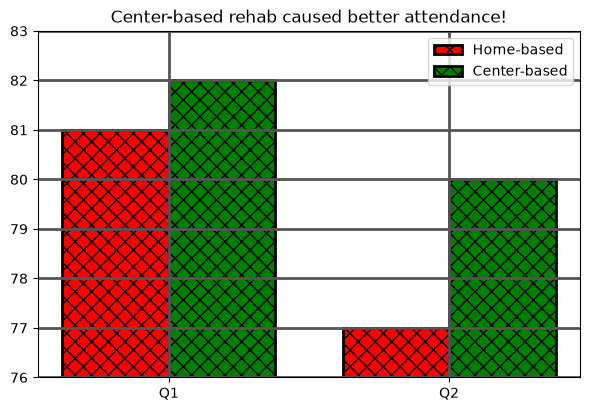

In [5]:
attendance = pd.read_csv(ATTENDANCE_PATH)
display(attendance)

quarters = ["Q1", "Q2"]
x = np.arange(len(quarters))  # [0 1]: one position per quarter
width = 0.38
home = attendance.loc[attendance["program"] == "Home-based", "attended_pct"]
center = attendance.loc[attendance["program"] == "Center-based", "attended_pct"]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(x - width / 2, home, width, label="Home-based", color="red",
       hatch="xx", edgecolor="black", linewidth=2)
ax.bar(x + width / 2, center, width, label="Center-based", color="green",
       hatch="xx", edgecolor="black", linewidth=2)
ax.set_xticks(x, quarters)
ax.set_ylim(76, 83)
ax.grid(True, linewidth=2, color="#555555")
ax.set_title("Center-based rehab caused better attendance!")
ax.legend()
plt.show()

### 2.2 Write the critique

Fill in a `problem` and a `repair` for each category, then run the cell to save the critique.

> **Checkpoint: `output/visualization_evidence.json`**
> An object with the key `critique`: a list of five entries, each with the keys `category`, `problem`, and `repair`.

In [ ]:
critique = [
    {"category": "unsupported claim", "problem": "This claim is not supported by the data.", "repair": "Add supporting evidence or remove the claim."},  # TODO: fill in each problem and repair
    {"category": "truncated baseline", "problem": "The baseline is incomplete.", "repair": "Include all relevant baseline data."},
    {"category": "missing unit", "problem": "The units are missing.", "repair": "Add appropriate units to all measurements."},
    {"category": "color-only encoding", "problem": "The visualization uses only color to encode information.", "repair": "Use additional visual elements like shape or size to encode information."},
    {"category": "distracting decoration", "problem": "The visualization has unnecessary decorative elements.", "repair": "Remove or minimize decorative elements that do not add value."},
]

for entry in critique:
    print(f"{entry['category']}: {entry['problem']}")
    print(f"    repair: {entry['repair']}")

with open(EVIDENCE_PATH, "w", encoding="utf-8") as file:
    json.dump({"critique": critique}, file, indent=2, ensure_ascii=False)

### 2.3 Redesign the chart

> **Checkpoint: `output/critique_redesign.png`**
> Your redesigned chart as a PNG image.

In [ ]:
redesign_fig, redesign_ax = plt.subplots(figsize=(7, 4.5))

# TODO: draw the four bars again from home and center on redesign_ax, repairing each problem in your critique
# (README Task 2.3 lists the repairs)

# TODO: save redesign_fig to REDESIGN_PATH with dpi=150 and bbox_inches="tight"

plt.show()
bottom, top = redesign_ax.get_ylim()
print("y-axis runs from", bottom, "to", top)

## Task 3: Explain one finding to the program coordinator

### 3.1 Write the contract and save the supporting data

> **Checkpoint: `output/explanatory_supporting_data.csv`**
> The header line `program,visit_number,goal_met_pct`, then the eight rows of `data/followup_goals.csv`.

In [ ]:
followup = None  # TODO: read FOLLOWUP_PATH with pd.read_csv
# TODO: display followup

question = ""  # TODO: the comparison the chart should help the coordinator make
audience = ""  # TODO: who reads the chart and what they will use it for
intended_claim = ""  # TODO: the one descriptive conclusion the chart supports
y_measure = ""  # TODO: what the y-axis measures, with its unit
grain = ""  # TODO: what one row of the plotting table and one point on a line represent
data_types = {
    "program": "",  # TODO: categorical, quantitative, ordinal, or temporal
    "visit_number": "",  # TODO
    "goal_met_pct": "",  # TODO
}

supporting_data = None  # TODO: the three plotted columns of followup

# TODO: save supporting_data to SUPPORTING_DATA_PATH without the row index

round_trip = pd.read_csv(SUPPORTING_DATA_PATH)
print("shape:", round_trip.shape)
print("same as saved:", round_trip.equals(supporting_data))

### 3.2 Draw the explanatory chart

> **Checkpoint: `output/explanatory_chart.png`**
> Your explanatory line chart as a PNG image.

In [ ]:
home_goals = supporting_data.loc[supporting_data["program"] == "Home-based"]
center_goals = supporting_data.loc[supporting_data["program"] == "Center-based"]

explanatory_fig, explanatory_ax = plt.subplots(figsize=(8, 4.8))

# TODO: draw one line per program on explanatory_ax, with visit_number on x and goal_met_pct on y,
# and finish the chart as README Task 3.2 describes

# TODO: save explanatory_fig to EXPLANATORY_PATH with dpi=150 and bbox_inches="tight"

plt.show()

### 3.3 Write the text alternative and save the evidence

> **Checkpoint: `output/visualization_evidence.json`**
> The keys `critique`, `question`, `audience`, `intended_claim`, `y_measure`, `grain`, `data_types`, and `text_alternative`.

> **Checkpoint: `output/explanatory_text_alternative.txt`**
> The same paragraph as `text_alternative` in the JSON.

In [ ]:
text_alternative = ""  # TODO: one paragraph, as README Task 3.3 describes

visualization_evidence = {
    "critique": critique,
    # TODO: add question, audience, intended_claim, y_measure, grain, data_types, and text_alternative
}

# TODO: save visualization_evidence to EVIDENCE_PATH with json.dump, as the Task 2.2 cell does

# TODO: write text_alternative to TEXT_ALTERNATIVE_PATH

with open(EVIDENCE_PATH, encoding="utf-8") as file:
    saved = json.load(file)
print(list(saved))

### 3.4 Review the saved charts

Open `output/critique_redesign.png` and `output/explanatory_chart.png`, and answer each question with what you see in them.

1. Printed in grayscale, how would a reader still tell the two programs apart in each chart?
2. Where does the explanatory chart's annotation point, and does its wording stay within what these eight rows can show?
3. Is any text cut off or overlapping in either saved PNG? If so, what did you change?
4. What limitation remains that no chart design can fix?

TODO: Replace this line with your answers.

## Fresh-run check

Click **Restart**, then **Run All**. The last cell prints your score and what to fix.

In [ ]:
from check_assignment import run_checks

_ = run_checks()